In [ ]:
import pandas as pd #ap24110010559
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report


In [ ]:
from google.colab import files

uploaded = files.upload()

df = pd.read_csv('titanic.csv')

print(df.head())

Saving titanic.csv to titanic.csv
   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            3

In [ ]:
print(df.shape)


(891, 12)


In [ ]:
print(df.info())


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB
None


In [ ]:
X = df[['Pclass', 'Sex', 'Age',
        'SibSp', 'Parch', 'Fare', 'Embarked']]

y = df['Survived']


In [ ]:
X = Passenger information
y = Survival prediction


SyntaxError: invalid syntax (669224309.py, line 1)

In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder

numeric_features = ['Pclass', 'Age', 'SibSp', 'Parch', 'Fare']

categorical_features = ['Sex', 'Embarked']

numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median'))
])

categorical_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OneHotEncoder(handle_unknown='ignore'))
])

preprocessor = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
])


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)


In [ ]:
model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', RandomForestClassifier(
        n_estimators=100,
        criterion='gini',
        max_depth=5,
        random_state=42
    ))
])


In [ ]:
model.fit(X_train, y_train)

print("Model Training Completed!")


Model Training Completed!


In [ ]:
y_pred = model.predict(X_test)

print(y_pred)


[0 0 0 0 1 0 1 0 0 0 0 0 1 0 0 0 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0 1 0 0 0 0 0
 0 0 1 0 1 0 1 1 0 0 0 1 1 1 0 1 0 0 0 0 0 1 0 1 1 0 0 0 0 1 0 0 0 1 0 1 1
 0 0 0 0 0 0 0 0 0 0 1 0 0 0 0 1 0 0 0 0 0 1 1 0 0 0 0 1 1 1 0 0 0 0 0 0 0
 0 0 0 1 0 0 0 0 0 0 1 0 0 0 0 0 0 0 0 0 0 1 0 0 0 1 0 1 0 0 0 1 0 0 0 0 0
 1 1 0 0 1 1 0 1 0 0 0 1 0 1 1 1 1 0 0 0 1 0 0 0 0 0 1 0 0 1 0]


In [ ]:
[0 1 1 0 1 0 0 1 1 0]


SyntaxError: invalid syntax. Perhaps you forgot a comma? (1548295806.py, line 1)

In [ ]:
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy * 100, "%")


Model Accuracy: 81.56424581005587 %


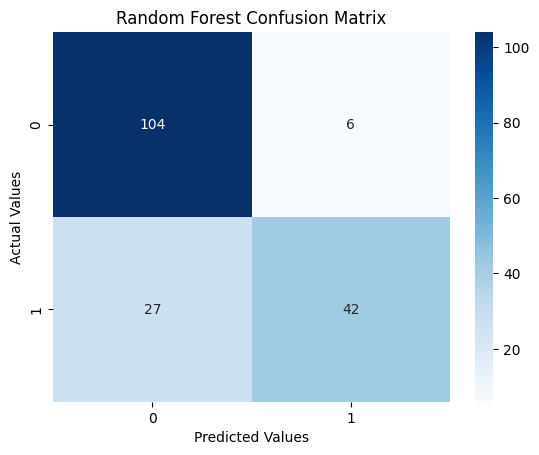

In [ ]:
cm = confusion_matrix(y_test, y_pred)

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")

plt.title("Random Forest Confusion Matrix")

plt.show()


In [ ]:
print(classification_report(y_test, y_pred))


              precision    recall  f1-score   support

           0       0.79      0.95      0.86       110
           1       0.88      0.61      0.72        69

    accuracy                           0.82       179
   macro avg       0.83      0.78      0.79       179
weighted avg       0.83      0.82      0.81       179



In [ ]:
feature_names = model.named_steps[
    'preprocessor'   #ap24110010559
].get_feature_names_out()

importance = model.named_steps[
    'classifier'
].feature_importances_

feature_importance = pd.DataFrame({
    'Feature': feature_names,
    'Importance': importance
})

feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

print(feature_importance)


           Feature  Importance
6    cat__Sex_male    0.288087
5  cat__Sex_female    0.230495
4        num__Fare    0.147190
0      num__Pclass    0.126602
1         num__Age    0.105375
2       num__SibSp    0.033575
3       num__Parch    0.029834
9  cat__Embarked_S    0.017461
7  cat__Embarked_C    0.012945
8  cat__Embarked_Q    0.008437


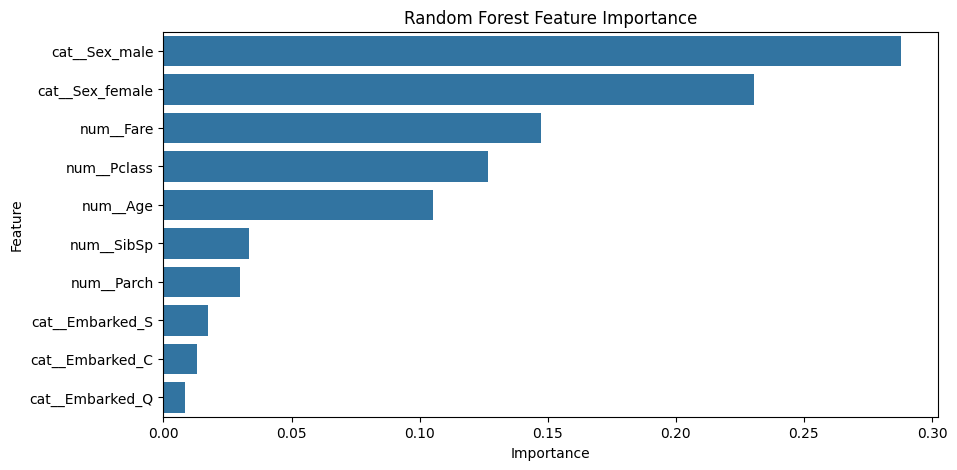

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x='Importance',
    y='Feature',
    data=feature_importance
)

plt.title("Random Forest Feature Importance")

plt.show()


In [ ]:
new_passenger = pd.DataFrame({
    'Pclass': [1],
    'Sex': ['female'],
    'Age': [25],
    'SibSp': [0],
    'Parch': [0],
    'Fare': [80],
    'Embarked': ['S']
})

prediction = model.predict(new_passenger)

if prediction[0] == 1:
    print("Passenger is predicted to SURVIVE")
else:
    print("Passenger is predicted NOT TO SURVIVE")  #ap24110010559


Passenger is predicted to SURVIVE
